# Application 2B — Carseats: categorical inputs and probabilities

**Question:** How do trees use categorical features, and how should we evaluate their probabilities?

The local `Carseats.csv` contains 400 stores/markets. Define high sales as
$Y=\mathbf1\{Sales>8\}$, with sales measured in thousands of units.
**Exclude Sales from every predictor set** because it defines the outcome.

Use training-fitted one-hot encoding for `ShelveLoc`, `Urban`, and `US`; an unseen category gets
all-zero indicators. Compare a training-prevalence baseline, a logistic baseline, a depth/leaf-selected
Gini tree, and a separately pruned tree. Use training CV Brier score to select both settings and
the final probability model. This allows the logistic comparison to win if the evidence favors it.
Draw a separate prespecified shallow tree for interpretation.

**Protocol:** stratified 60/20/20 split, seed 23; the same five training folds for every candidate.
Use validation only for probability diagnostics and a threshold for false-positive cost 1 and
false-negative cost 3. Freeze the fitted model before test evaluation. Run from `FocusedContent`
or the course root with the course requirements. See [the focused guide](02_decision_trees_and_random_forests.pdf).

## 1. Load data, define the target, and reserve partitions

Check that the file contains 400 rows and 164 positive labels. This CSV has no exported index column.
Separate numerical and categorical features explicitly. Preserve original row IDs for split checks.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import brier_score_loss, confusion_matrix, accuracy_score, precision_score, recall_score

course_dir = Path.cwd()
if not (course_dir / "An-Introduction-to-Statistical-Learning-Python-main").exists():
    course_dir = course_dir.parent
path = course_dir / "An-Introduction-to-Statistical-Learning-Python-main" / "data" / "Carseats.csv"
data = pd.read_csv(path)
assert data.shape == (400, 11) and data.notna().all().all()
y = (data["Sales"] > 8).astype(int)
assert y.sum() == 164
X = data.drop(columns="Sales")
categorical = ["ShelveLoc", "Urban", "US"]
numeric = [column for column in X.columns if column not in categorical]
train_valid_ids, test_ids = train_test_split(data.index, test_size=0.2, random_state=23, stratify=y)
train_ids, valid_ids = train_test_split(train_valid_ids, test_size=0.25, random_state=23,
                                        stratify=y.loc[train_valid_ids])
assert set(train_ids).isdisjoint(valid_ids)
assert set(train_ids).isdisjoint(test_ids)
assert set(valid_ids).isdisjoint(test_ids)
X_train, y_train = X.loc[train_ids], y.loc[train_ids].to_numpy()
X_valid, y_valid = X.loc[valid_ids], y.loc[valid_ids].to_numpy()
X_test, y_test = X.loc[test_ids], y.loc[test_ids].to_numpy()
print("Rows:", len(train_ids), len(valid_ids), len(test_ids))
print("Training class counts:", np.bincount(y_train))
print("Numeric inputs:", numeric)
print("Categorical inputs:", categorical)
assert "Sales" not in X_train.columns

Rows: 240 80 80
Training class counts: [142  98]
Numeric inputs: ['CompPrice', 'Income', 'Advertising', 'Population', 'Price', 'Age', 'Education']
Categorical inputs: ['ShelveLoc', 'Urban', 'US']


## 2. Build fresh preprocessing inside each training fold

Trees use unscaled numerical features. The logistic comparison scales only numerical features and
uses one-hot categorical indicators. Fix its slope penalty at `C=1` and report this as a baseline,
not a fully tuned logistic search. Every call below makes a fresh pipeline.

Brier score is mean squared probability error and stays finite for pure leaves.
For reported log loss, explicitly clip every candidate's probabilities to $[10^{-12},1-10^{-12}]$.
This is a reporting convention, not smoothing learned by the tree.

In [2]:
def make_pipeline(model, scale_numeric=False):
    numeric_transform = StandardScaler() if scale_numeric else "passthrough"
    preprocessing = ColumnTransformer([
        ("numeric", numeric_transform, numeric),
        ("categorical", OneHotEncoder(handle_unknown="ignore", sparse_output=False), categorical),
    ], verbose_feature_names_out=False)
    return Pipeline([("features", preprocessing), ("model", model)])

def clipped_log_loss(labels, probabilities):
    p = np.clip(probabilities, 1e-12, 1 - 1e-12)
    return -np.mean(labels * np.log(p) + (1 - labels) * np.log1p(-p))

folds = list(StratifiedKFold(n_splits=5, shuffle=True, random_state=23).split(X_train, y_train))

def cv_brier(pipeline):
    scores = []
    for fit_rows, score_rows in folds:
        # fit() replaces the preprocessing and estimator state on this fold only.
        pipeline.fit(X_train.iloc[fit_rows], y_train[fit_rows])
        p = pipeline.predict_proba(X_train.iloc[score_rows])[:, 1]
        scores.append(brier_score_loss(y_train[score_rows], p))
    return np.mean(scores), np.std(scores, ddof=1)

## 3. Select tree settings, then the probability model

Compare depths 1, 2, 3, 5, and unlimited with minimum leaf sizes 2, 5, 10, and 20.
Separately grow trees with minimum leaf size 2 and pruning alpha in
$\{0,0.001,0.005,0.01,0.02,0.05\}$, using normalized Gini risk.
Choose each setting by mean training-fold Brier score, then compare those winners with the
baseline and logistic model. Exact ties use table order. Fold SD is descriptive, not a confidence interval.

In [3]:
depth_rows = []
for depth in [1, 2, 3, 5, None]:
    for leaf_size in [2, 5, 10, 20]:
        tree = DecisionTreeClassifier(criterion="gini", max_depth=depth,
                                      min_samples_leaf=leaf_size, random_state=31)
        mean, sd = cv_brier(make_pipeline(tree))
        depth_rows.append({"depth": depth if depth is not None else "unlimited",
                           "leaf size": leaf_size, "CV Brier": mean, "fold SD": sd})
depth_cv = pd.DataFrame(depth_rows)
best_depth_row = depth_cv.loc[depth_cv["CV Brier"].idxmin()]
best_depth = None if best_depth_row["depth"] == "unlimited" else int(best_depth_row["depth"])
best_leaf = int(best_depth_row["leaf size"])
pruning_rows = []
for alpha in [0, 0.001, 0.005, 0.01, 0.02, 0.05]:
    tree = DecisionTreeClassifier(criterion="gini", min_samples_leaf=2, ccp_alpha=alpha, random_state=31)
    mean, sd = cv_brier(make_pipeline(tree))
    pruning_rows.append({"alpha": alpha, "CV Brier": mean, "fold SD": sd})
pruning_cv = pd.DataFrame(pruning_rows)
best_pruning_row = pruning_cv.loc[pruning_cv["CV Brier"].idxmin()]
best_alpha = float(best_pruning_row["alpha"])
logistic = make_pipeline(LogisticRegression(C=1, solver="lbfgs", max_iter=2000, tol=1e-8), True)
logistic_mean, logistic_sd = cv_brier(logistic)
baseline_scores = []
for fit_rows, score_rows in folds:
    p = np.full(len(score_rows), y_train[fit_rows].mean())
    baseline_scores.append(brier_score_loss(y_train[score_rows], p))
comparison = pd.DataFrame([
    {"model": "Prevalence baseline", "CV Brier": np.mean(baseline_scores)},
    {"model": "Logistic C=1", "CV Brier": logistic_mean},
    {"model": "Depth/leaf tree", "CV Brier": best_depth_row["CV Brier"]},
    {"model": "Pruned tree", "CV Brier": best_pruning_row["CV Brier"]},
])
selected_name = comparison.loc[comparison["CV Brier"].idxmin(), "model"]
display(depth_cv)
display(pruning_cv)
display(comparison)
print("Frozen probability model:", selected_name)
print("Tree settings:", best_depth, best_leaf, "pruning alpha:", best_alpha)

models = {
    "Logistic C=1": logistic,
    "Depth/leaf tree": make_pipeline(DecisionTreeClassifier(max_depth=best_depth,
                        min_samples_leaf=best_leaf, random_state=31)),
    "Pruned tree": make_pipeline(DecisionTreeClassifier(min_samples_leaf=2,
                       ccp_alpha=best_alpha, random_state=31)),
}
for model in models.values():
    model.fit(X_train, y_train)
    np.testing.assert_array_equal(model.classes_, [0, 1])
assert models["Logistic C=1"].named_steps["model"].n_iter_[0] < 2000
baseline_probability = y_train.mean()

def probabilities(name, inputs):
    if name == "Prevalence baseline":
        return np.full(len(inputs), baseline_probability)
    return models[name].predict_proba(inputs)[:, 1]

,depth,leaf size,CV Brier,fold SD
0,1,2,0.225188,0.012938
1,1,5,0.225188,0.012938
2,1,10,0.225188,0.012938
3,1,20,0.225188,0.012938
4,2,2,0.239195,0.026731
5,2,5,0.239195,0.026731
6,2,10,0.235667,0.019860
7,2,20,0.227211,0.041734
8,3,2,0.207578,0.025009
9,3,5,0.216807,0.040065


,alpha,CV Brier,fold SD
0,0.000,0.270139,0.046019
1,0.001,0.270139,0.046019
2,0.005,0.264208,0.031671
3,0.010,0.244095,0.011482
4,0.020,0.228800,0.019160
5,0.050,0.222230,0.014614


,model,CV Brier
0,Prevalence baseline,0.241656
1,Logistic C=1,0.082353
2,Depth/leaf tree,0.186140
3,Pruned tree,0.222230


Frozen probability model: Logistic C=1
Tree settings: None 10 pruning alpha: 0.05


## 4. Read a shallow tree and translate two paths

Fit a separate depth-two Gini tree with minimum leaf size 10 for illustration. It does not replace
the CV-selected model. Annotate each leaf with its training count and positive fraction.
A one-hot test such as `ShelveLoc_Good <= 0.5` means **not Good** among observed categories.
Show two root-to-leaf paths in ordinary feature terms, including their probability estimates.

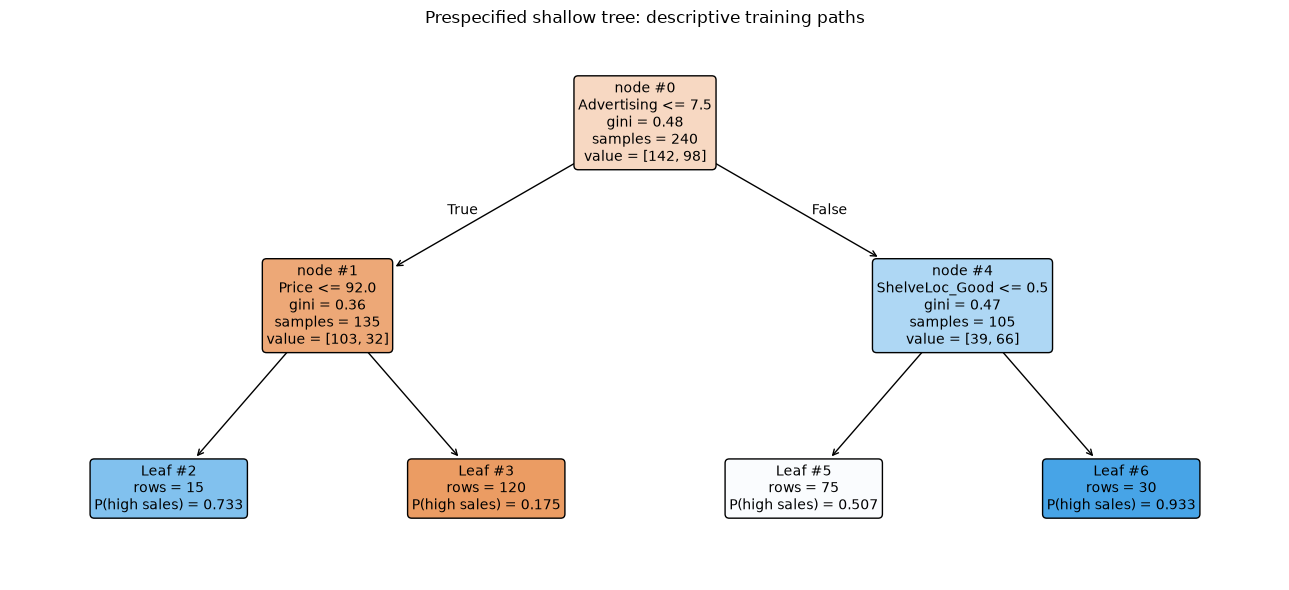

If Advertising <= 7.50 AND Price <= 92.00, predict high-sales probability 0.733.
If Advertising > 7.50 AND ShelveLoc is Good, predict high-sales probability 0.933.


In [4]:
shallow = make_pipeline(DecisionTreeClassifier(max_depth=2, min_samples_leaf=10, random_state=31))
shallow.fit(X_train, y_train)
encoder = shallow.named_steps["features"]
tree = shallow.named_steps["model"]
feature_names = encoder.get_feature_names_out()
plt.figure(figsize=(13, 6))
annotations = plot_tree(tree, feature_names=feature_names, node_ids=True,
                        filled=True, rounded=True, precision=2, fontsize=10)
for annotation in annotations:
    first_line = annotation.get_text().splitlines()[0]
    if "#" not in first_line:  # Skip the True/False edge labels.
        continue
    node = int(first_line.split("#")[-1])
    if tree.tree_.children_left[node] == -1:
        counts = tree.tree_.value[node, 0]
        p = counts[1] / counts.sum()
        annotation.set_text(f"Leaf #{node}\nrows = {tree.tree_.n_node_samples[node]}\nP(high sales) = {p:.3f}")
plt.title("Prespecified shallow tree: descriptive training paths")
plt.tight_layout()
plt.show()

encoded = encoder.transform(X_train)
leaf_ids = tree.apply(encoded)
leaves = np.unique(leaf_ids)
for leaf in [leaves[0], leaves[-1]]:
    row = np.flatnonzero(leaf_ids == leaf)[0]
    path_nodes = tree.decision_path(encoded[[row]]).indices
    conditions = []
    for node in path_nodes:
        j = tree.tree_.feature[node]
        if j < 0:
            continue
        name = feature_names[j]
        threshold = tree.tree_.threshold[node]
        goes_left = encoded[row, j] <= threshold
        category_column = next((column for column in categorical if name.startswith(column + "_")), None)
        if category_column is not None:
            category = name[len(category_column) + 1:]
            conditions.append(f"{category_column} {'is not' if goes_left else 'is'} {category}")
        else:
            conditions.append(f"{name} {'<=' if goes_left else '>'} {threshold:.2f}")
    p = tree.predict_proba(encoded[[row]])[0, 1]
    print("If " + " AND ".join(conditions) + f", predict high-sales probability {p:.3f}.")

## 5. Validation probability audit and threshold selection

Report Brier and clipped log loss for the frozen candidates. For the selected model, use five
fixed probability bins; display counts and omit empty bins from the calibration plot.
Select a threshold from 0.01 to 0.99 in steps of 0.01, including 0.25 and 0.5,
to minimize $(FP+3FN)/m$. Predict 1 at equality; ties in cost choose the largest threshold.
Keep the model fitted on the training partition after choosing the threshold.

,Brier,clipped log loss
model,,
Prevalence baseline,0.242361,0.677791
Logistic C=1,0.079918,0.274139
Depth/leaf tree,0.207644,1.823761
Pruned tree,0.229876,0.652918


,mean_probability,event_rate,count
bin,,,
"(-0.001, 0.2]",0.069391,0.054054,37
"(0.2, 0.4]",0.288193,0.333333,9
"(0.4, 0.6]",0.512789,0.250000,8
"(0.6, 0.8]",0.707028,1.000000,4
"(0.8, 1.0]",0.924634,1.000000,22


Frozen threshold: 0.31


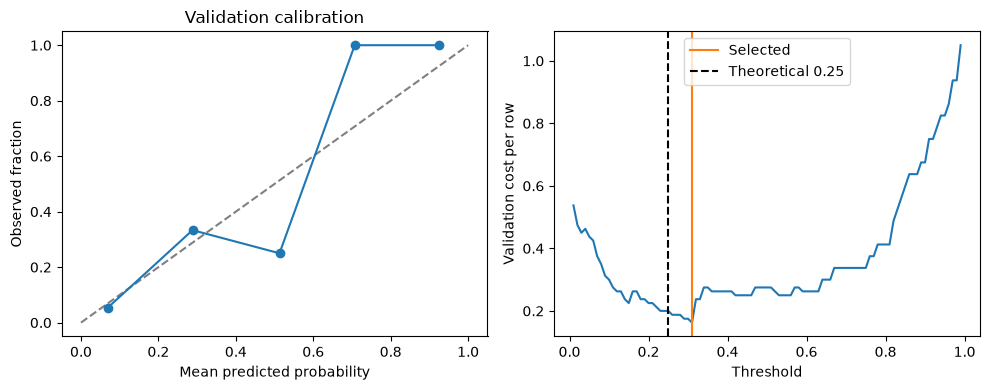

In [5]:
validation_rows = []
for name in comparison["model"]:
    p = probabilities(name, X_valid)
    validation_rows.append({"model": name, "Brier": brier_score_loss(y_valid, p),
                            "clipped log loss": clipped_log_loss(y_valid, p)})
display(pd.DataFrame(validation_rows).set_index("model"))
p_valid = probabilities(selected_name, X_valid)
calibration = pd.DataFrame({"p": p_valid, "y": y_valid})
calibration["bin"] = pd.cut(calibration["p"], np.linspace(0, 1, 6), include_lowest=True)
calibration_table = calibration.groupby("bin", observed=True).agg(
    mean_probability=("p", "mean"), event_rate=("y", "mean"), count=("y", "size"))
display(calibration_table)
threshold_rows = []
for threshold in np.arange(1, 100) / 100:
    prediction = p_valid >= threshold
    tn, fp, fn, tp = confusion_matrix(y_valid, prediction, labels=[0, 1]).ravel()
    threshold_rows.append({"threshold": threshold, "cost": fp + 3 * fn})
threshold_results = pd.DataFrame(threshold_rows)
minimum = threshold_results["cost"].min()
best_threshold = threshold_results.loc[threshold_results["cost"] == minimum, "threshold"].max()
print("Frozen threshold:", best_threshold)
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
axes[0].plot([0, 1], [0, 1], "--", color="gray")
axes[0].plot(calibration_table["mean_probability"], calibration_table["event_rate"], "o-")
axes[0].set(xlabel="Mean predicted probability", ylabel="Observed fraction", title="Validation calibration")
axes[1].plot(threshold_results["threshold"], threshold_results["cost"] / len(valid_ids))
axes[1].axvline(best_threshold, color="tab:orange", label="Selected")
axes[1].axvline(0.25, color="black", linestyle="--", label="Theoretical 0.25")
axes[1].set(xlabel="Threshold", ylabel="Validation cost per row")
axes[1].legend()
plt.tight_layout()
plt.show()

## 6. Final test probabilities and decisions

Compare the four frozen probability candidates; do not reselect from test scores. For the selected
model, report decisions at 0.5, theoretical 0.25, and the validation threshold. Include the prevalence
baseline at 0.25. Report undefined precision/recall as zero explicitly (`zero_division=0`).
This test has only 80 rows: treat small differences with caution.

In [6]:
probability_rows = []
for name in comparison["model"]:
    p = probabilities(name, X_test)
    probability_rows.append({"model": name, "test Brier": brier_score_loss(y_test, p),
                             "test clipped log loss": clipped_log_loss(y_test, p)})
test_probability_results = pd.DataFrame(probability_rows).set_index("model")
display(test_probability_results)
p_test = probabilities(selected_name, X_test)
policies = [
    ("Selected model at 0.5", p_test, 0.5),
    ("Selected model at 0.25", p_test, 0.25),
    ("Validation-selected policy", p_test, best_threshold),
    ("Prevalence baseline at 0.25", np.full(len(test_ids), baseline_probability), 0.25),
]
policy_rows = []
for name, p, threshold in policies:
    prediction = p >= threshold
    tn, fp, fn, tp = confusion_matrix(y_test, prediction, labels=[0, 1]).ravel()
    policy_rows.append({"policy": name, "threshold": threshold, "TN": tn, "FP": fp, "FN": fn, "TP": tp,
                        "accuracy": accuracy_score(y_test, prediction),
                        "precision": precision_score(y_test, prediction, zero_division=0),
                        "recall": recall_score(y_test, prediction, zero_division=0),
                        "cost per row": (fp + 3 * fn) / len(test_ids)})
test_policy_results = pd.DataFrame(policy_rows).set_index("policy")
display(test_policy_results)
chosen_matrix = confusion_matrix(y_test, p_test >= best_threshold, labels=[0, 1])
display(pd.DataFrame(chosen_matrix, index=["Actual 0", "Actual 1"], columns=["Predicted 0", "Predicted 1"]))

,test Brier,test clipped log loss
model,,
Prevalence baseline,0.242361,0.677791
Logistic C=1,0.096407,0.307515
Depth/leaf tree,0.265255,3.240530
Pruned tree,0.272976,0.747249


,threshold,TN,FP,FN,TP,accuracy,precision,recall,cost per row
policy,,,,,,,,,
Selected model at 0.5,0.50,41,6,5,28,0.8625,0.823529,0.848485,0.2625
Selected model at 0.25,0.25,34,13,2,31,0.8125,0.704545,0.939394,0.2375
Validation-selected policy,0.31,37,10,2,31,0.8500,0.756098,0.939394,0.2000
Prevalence baseline at 0.25,0.25,0,47,0,33,0.4125,0.412500,1.000000,0.5875


,Predicted 0,Predicted 1
Actual 0,37,10
Actual 1,2,31


## Interpret the results

- Which family wins by training CV? A tree lecture does not require a tree to win every comparison.
- Compare leaf sample counts with probability certainty. Why can a pure small leaf have poor log loss?
- Explain the two printed paths using the original shelf-location categories rather than arbitrary integer codes.
- Does the validation-selected threshold outperform 0.25 on this test? It is allowed not to;
  the validation sample is small and threshold selection is noisy.
- These are predictive associations in an observational teaching dataset, not causal effects of store decisions.

**In the saved run:** training CV selects the logistic baseline over both tree candidates.
Its test Brier score is about 0.0964, versus 0.2424 for prevalence alone. Validation selects
threshold 0.31. On the 80 test rows that policy gives 10 false positives and 2 false negatives,
with cost 0.20 per row. The tree diagram remains useful for understanding conditional rules,
even though its family did not win this particular comparison.